In [1]:
import torch
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

CUDA: True
GPU: Tesla T4


In [2]:
%pip install transformers accelerate scikit-learn torchvision datasets -q

In [3]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [4]:
from transformers import AutoImageProcessor, AutoModelForImageClassification
import torch

model_path = "/content/drive/MyDrive/ai-skin-care/vision-model-final"

print("Loading model from Drive...")
processor = AutoImageProcessor.from_pretrained(model_path)
model = AutoModelForImageClassification.from_pretrained(model_path).to("cuda")
model.eval()

# Class names (training wale order mein)
class_names = ['Acne', 'Eczema', 'Psoriasis', 'SkinCancer', 'Sun_Sunlight_Damage', 'Unknown_Normal']

print("\n✅ Model loaded!")
print(f"Parameters: {model.num_parameters():,}")
print(f"Device: {model.device}")
print(f"Classes: {class_names}")

Loading model from Drive...


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]


✅ Model loaded!
Parameters: 85,803,270
Device: cuda:0
Classes: ['Acne', 'Eczema', 'Psoriasis', 'SkinCancer', 'Sun_Sunlight_Damage', 'Unknown_Normal']


✅ Found 1 test images:
   - testImage .jpg



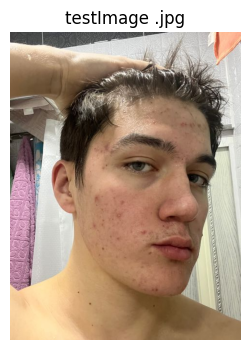

🎯 testImage .jpg
   Prediction: Acne (36.90%)
   Top 3:
     1. Acne: 36.90%
     2. Unknown_Normal: 21.03%
     3. Sun_Sunlight_Damage: 12.23%
──────────────────────────────────────────────────


In [6]:
from PIL import Image
import matplotlib.pyplot as plt
import torch
import os

test_folder = "/content/drive/MyDrive/ai-skin-care"

# Sirf image files lo (folders skip karo)
image_files = [f for f in os.listdir(test_folder) 
               if f.lower().endswith(('.jpg', '.jpeg', '.png')) and
               os.path.isfile(os.path.join(test_folder, f))]

print(f"✅ Found {len(image_files)} test images:")
for f in image_files:
    print(f"   - {f}")
print()

for filename in image_files:
    image_path = os.path.join(test_folder, filename)
    image = Image.open(image_path).convert("RGB")
    
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis("off")
    plt.title(filename)
    plt.show()
    
    inputs = processor(image, return_tensors="pt").to("cuda")
    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.softmax(outputs.logits, dim=1)
        pred_idx = probs.argmax().item()
        confidence = probs.max().item()
    
    print(f"🎯 {filename}")
    print(f"   Prediction: {class_names[pred_idx]} ({confidence:.2%})")
    
    top3 = torch.topk(probs, 3)
    print("   Top 3:")
    for i, (prob, idx) in enumerate(zip(top3.values[0], top3.indices[0])):
        print(f"     {i+1}. {class_names[idx]}: {prob.item():.2%}")
    print("─" * 50)

In [7]:
from datasets import load_dataset
from collections import Counter
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# Data load (same seed = same split)
data_path = "/content/drive/MyDrive/ai-skin-care/SkinDisease_balanced"
dataset = load_dataset("imagefolder", data_dir=data_path)
dataset = dataset["train"].train_test_split(test_size=0.2, seed=42)

class_names = dataset["train"].features["label"].names
print("Classes:", class_names)
print(f"Test size: {len(dataset['test'])}")
print(f"Train size: {len(dataset['train'])}")

# Test set distribution
test_labels = dataset["test"]["label"]
counter = Counter(test_labels)
print("\nTest distribution:")
for idx, count in sorted(counter.items()):
    print(f"  {class_names[idx]}: {count}")

Resolving data files:   0%|          | 0/1799 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Classes: ['Acne', 'Eczema', 'Psoriasis', 'SkinCancer', 'Sun_Sunlight_Damage', 'Unknown_Normal']
Test size: 360
Train size: 1439

Test distribution:
  Acne: 62
  Eczema: 56
  Psoriasis: 60
  SkinCancer: 66
  Sun_Sunlight_Damage: 62
  Unknown_Normal: 54


In [8]:
model.eval()
all_preds = []
all_labels = []
all_probs = []

test_data = dataset["test"]
batch_size = 16

for i in range(0, len(test_data), batch_size):
    batch = test_data[i:i+batch_size]
    images = [img.convert("RGB") for img in batch["image"]]
    labels = batch["label"]
    
    inputs = processor(images, return_tensors="pt").to("cuda")
    
    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.softmax(outputs.logits, dim=1)
        preds = probs.argmax(dim=1).cpu().numpy()
    
    all_preds.extend(preds)
    all_labels.extend(labels)
    all_probs.extend(probs.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# Metrics
accuracy = accuracy_score(all_labels, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(
    all_labels, all_preds, average="weighted"
)

print("\n📊 Test Set Evaluation:")
print(f"Accuracy:  {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")
print(f"F1 Score:  {f1:.2%}")
print(f"Total: {len(all_labels)} images")


📊 Test Set Evaluation:
Accuracy:  80.00%
Precision: 80.11%
Recall:    80.00%
F1 Score:  80.01%
Total: 360 images


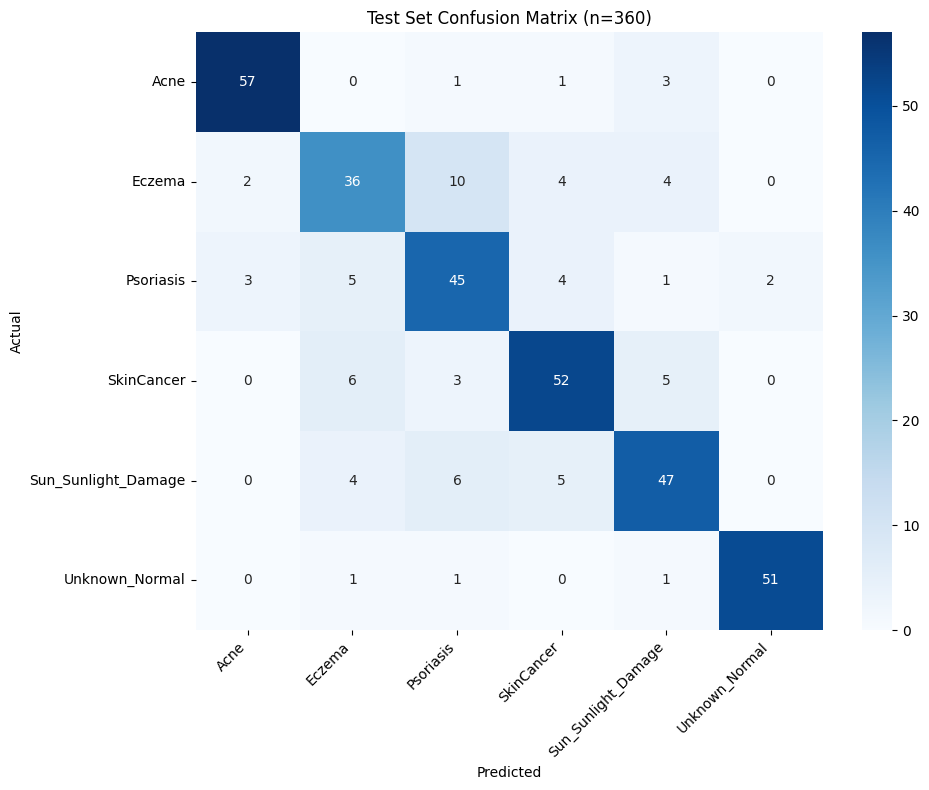

In [9]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Test Set Confusion Matrix (n={len(all_labels)})")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()